In [1]:
!pip install gdown pandas numpy matplotlib opencv-python torch torchvision tqdm -q
!pip install git+https://github.com/cvg/LightGlue.git

  Cloning https://github.com/cvg/LightGlue.git to c:\users\zhenu\appdata\local\temp\pip-req-build-09qrwgoa
  Resolved https://github.com/cvg/LightGlue.git to commit 5a650c444718caffc2669dc0094cde908f42dd73
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/cvg/LightGlue.git 'C:\Users\zhenu\AppData\Local\Temp\pip-req-build-09qrwgoa'


In [2]:
import os
import random
import sys

PROJECT_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
SRC_DIR = os.path.join(PROJECT_ROOT, "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd
from tqdm import tqdm

from model import UAVEmbedderMultiTask
from train import build_training_pairs, download_dataset_if_needed, load_coords_df, train
from evaluate import (
    calculate_haversine_distance,
    download_weights_if_needed,
    find_gt_tile,
    generate_tiles_with_metadata,
    load_image_for_lightglue,
    pixel_to_gps,
)

Image.MAX_IMAGE_PIXELS = None
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
WEIGHTS_PATH = os.path.join(PROJECT_ROOT, "weights", "uav_multitask_best.pth")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
base_dir = download_dataset_if_needed(DATA_DIR)
weights_path = download_weights_if_needed(WEIGHTS_PATH)

Завантаження ваг...


Downloading...
From (original): https://drive.google.com/uc?id=1vAtU3O-q0S9IlVUN9LvGkXCjX92nkhsc
From (redirected): https://drive.google.com/uc?id=1vAtU3O-q0S9IlVUN9LvGkXCjX92nkhsc&confirm=t&uuid=a47ff6b0-57d6-4ab9-8a3c-37a1a1eabc96
To: /content/dataset/UAV_VisLoc_dataset/Weights/uav_multitask_best.pth
100%|██████████| 349M/349M [00:07<00:00, 45.3MB/s]

Ваги успішно завантажено!


In [ ]:
test_dir = os.path.join(base_dir, "06")
drone_dir = os.path.join(test_dir, "drone")

df_coords = load_coords_df(base_dir)
df_uav = pd.read_csv(os.path.join(test_dir, "06.csv"))
df_uav.columns = df_uav.columns.str.strip()

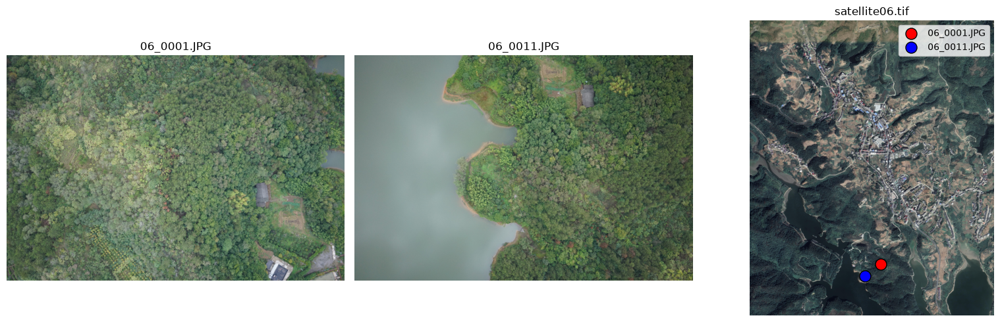

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

img_1_name = df_uav.iloc[0]["filename"]
axes[0].imshow(Image.open(os.path.join(drone_dir, img_1_name)))
axes[0].set_title(f"UAV Frame: {img_1_name}")
axes[0].axis("off")

img_2_name = df_uav.iloc[10]["filename"]
axes[1].imshow(Image.open(os.path.join(drone_dir, img_2_name)))
axes[1].set_title(f"UAV Frame: {img_2_name}")
axes[1].axis("off")

sat_img_path = os.path.join(test_dir, "satellite06.tif")
sat_img = Image.open(sat_img_path)
orig_w, orig_h = sat_img.size
sat_img.thumbnail((1024, 1024))
disp_w, disp_h = sat_img.size

axes[2].imshow(sat_img)
axes[2].set_title("satellite06.tif (Ground Truth Positions)")
axes[2].axis("off")

sat_meta = df_coords[df_coords["mapname"] == "satellite06.tif"].iloc[0]
lt_lat, lt_lon = sat_meta["LT_lat_map"], sat_meta["LT_lon_map"]
rb_lat, rb_lon = sat_meta["RB_lat_map"], sat_meta["RB_lon_map"]

def gps_to_pixel(lat, lon):
    x_pct = (lon - lt_lon) / (rb_lon - lt_lon)
    y_pct = (lat - lt_lat) / (rb_lat - lt_lat)
    return x_pct * disp_w, y_pct * disp_h

x1, y1 = gps_to_pixel(df_uav.iloc[0]["lat"], df_uav.iloc[0]["lon"])
axes[2].scatter(x1, y1, color="red", s=150, edgecolors="black", label=img_1_name)

x2, y2 = gps_to_pixel(df_uav.iloc[10]["lat"], df_uav.iloc[10]["lon"])
axes[2].scatter(x2, y2, color="blue", s=150, edgecolors="black", label=img_2_name)

axes[2].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 1. Triplet Sampling & Visualization

In [ ]:
training_pairs = build_training_pairs(base_dir, test_scene="06")

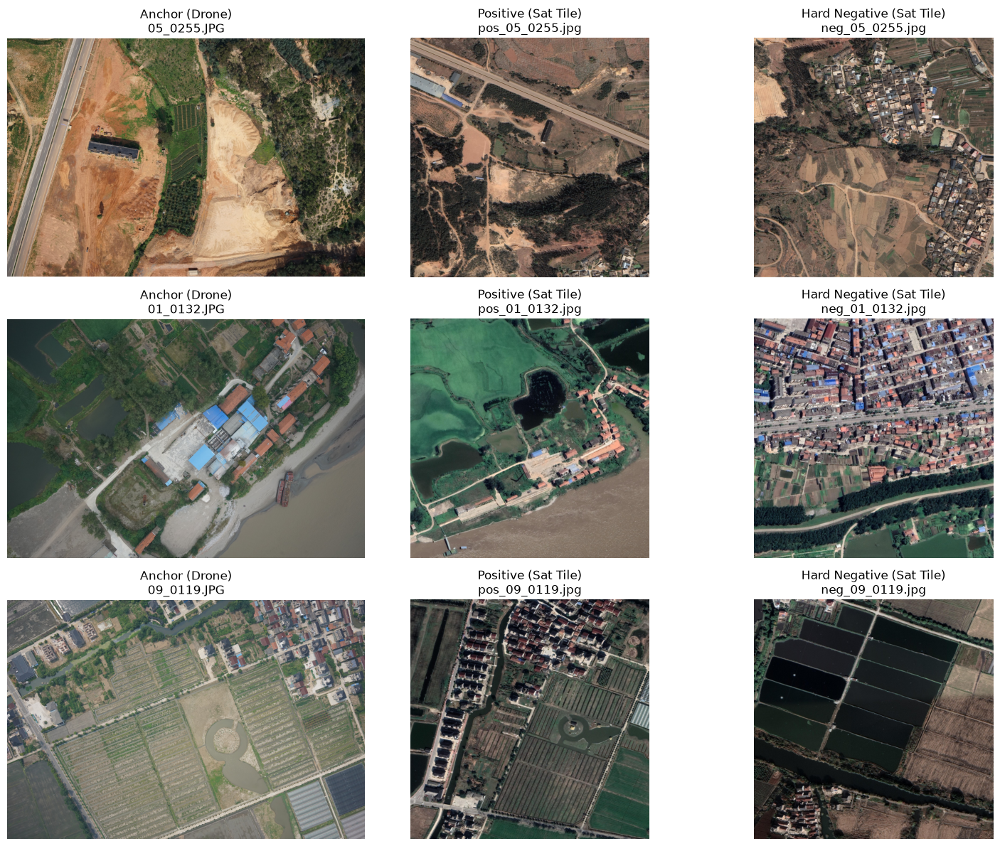

In [ ]:
def visualize_triplets(training_pairs, num_samples=3):
    samples = random.sample(training_pairs, min(num_samples, len(training_pairs)))
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 4 * num_samples))

    if num_samples == 1:
        axes = [axes]

    for i, pair in enumerate(samples):
        anchor_img = Image.open(pair['anchor']).convert('RGB')
        pos_img = Image.open(pair['positive']).convert('RGB')
        neg_img = Image.open(pair['negative']).convert('RGB')

        axes[i][0].imshow(anchor_img)
        axes[i][0].set_title(f"Anchor (Drone)\n{os.path.basename(pair['anchor'])}")
        axes[i][0].axis('off')

        axes[i][1].imshow(pos_img)
        axes[i][1].set_title(f"Positive (Sat Tile)\n{os.path.basename(pair['positive'])}")
        axes[i][1].axis('off')

        axes[i][2].imshow(neg_img)
        axes[i][2].set_title(f"Hard Negative (Sat Tile)\n{os.path.basename(pair['negative'])}")
        axes[i][2].axis('off')

    plt.tight_layout()
    plt.show()

visualize_triplets(training_pairs, num_samples=3)

## 2. Multi-Task Model Training

In [ ]:
# Uncomment to retrain from scratch (~1.5h on T4 GPU):
# from argparse import Namespace
# train(Namespace(
#     data_dir=DATA_DIR,
#     weights_dir=os.path.join(PROJECT_ROOT, "weights"),
#     test_scene="06",
#     batch_size=32,
#     epochs=30,
#     patience=4,
#     rot_weight=0.5,
#     num_workers=2,
#     seed=42,
# ))

Using cache found in C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Epoch 1/30 [VAL]: 100%|██████████| 29/29 [00:55<00:00,  1.91s/it, loss=0.7724]



Епоха 1 | Train Loss: 0.9220 | Val Loss: 0.7993


Epoch 2/30 [VAL]: 100%|██████████| 29/29 [00:41<00:00,  1.41s/it, loss=0.5713]



Епоха 2 | Train Loss: 0.6998 | Val Loss: 0.6869


Epoch 3/30 [VAL]: 100%|██████████| 29/29 [00:41<00:00,  1.42s/it, loss=0.5325]



Епоха 3 | Train Loss: 0.6007 | Val Loss: 0.6378


... (28 outputs left out)

Epoch 18/30 [VAL]: 100%|██████████| 29/29 [00:43<00:00,  1.52s/it, loss=0.5610]



Епоха 18 | Train Loss: 0.1753 | Val Loss: 0.5477


Epoch 19/30 [VAL]: 100%|██████████| 29/29 [00:41<00:00,  1.43s/it, loss=0.5935]



Епоха 19 | Train Loss: 0.1685 | Val Loss: 0.5552


## 3. Satellite Tiling & Coarse-to-Fine Evaluation

In [ ]:
sat_path = os.path.join(test_dir, f'satellite06.tif')
tiles_dir = os.path.join(test_dir, 'satellite_tiles')
print(f"Generating satellite tiles")
df_tiles_meta = generate_tiles_with_metadata(
    image_path=sat_path,
    output_dir=tiles_dir,
    tile_size=2048,
    stride=512
)
meta_csv_path = os.path.join(test_dir, 'tiles_metadata.csv')
df_tiles_meta.to_csv(meta_csv_path, index=False)

print(f"Total tiles created: {len(df_tiles_meta)}")

Генерація тайтлів папки


Рядки: 100%|██████████| 17/17 [00:04<00:00,  4.12it/s]

Папка завершена. Створено тайлів: 221


In [ ]:
def plot_custom(item, title):
    img0_base = cv2.cvtColor(cv2.imread(item["drone_path"]), cv2.COLOR_BGR2RGB)
    img0_base = cv2.resize(img0_base, (640, 640))

    M = cv2.getRotationMatrix2D((320.0, 320.0), item["best_angle"], 1.0)
    img0 = cv2.warpAffine(img0_base, M, (640, 640))

    img1 = cv2.cvtColor(cv2.imread(item["pred_tile_path"]), cv2.COLOR_BGR2RGB)
    img1 = cv2.resize(img1, (640, 640))

    if item["gt_tile_path"] and os.path.exists(item["gt_tile_path"]):
        img2 = cv2.cvtColor(cv2.imread(item["gt_tile_path"]), cv2.COLOR_BGR2RGB)
        img2 = cv2.resize(img2, (640, 640))
    else:
        img2 = np.zeros((640, 640, 3), dtype=np.uint8)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 8))
    fig.suptitle(title, fontsize=18, fontweight="bold", y=0.95)

    ax1.imshow(img0)
    ax1.set_title(f"UAV Frame (Rotation: {item['best_angle']}°)", fontsize=15, pad=10)
    ax1.axis("off")

    if item["is_top1"]:
        status, color = "HIT: Found in Top-1", "green"
    elif item["is_top5"]:
        status, color = "HIT: Found in Top-5", "orange"
    else:
        status, color = "MISS: Not in Top-5", "red"

    ax2.imshow(img1)
    ax2.set_title(f"Retrieved Tile ({status})", fontsize=15, pad=10, color=color)
    ax2.axis("off")

    ax3.imshow(img2)
    ax3.set_title("Ground Truth Tile", fontsize=15, pad=10)
    ax3.axis("off")

    if item["m_kps0"] is not None and item["m_kps1"] is not None:
        kps0, kps1 = item["m_kps0"], item["m_kps1"]
        indices = np.arange(len(kps0))
        if len(kps0) > 40:
            np.random.seed(42)
            indices = np.random.choice(indices, 40, replace=False)

        for i in indices:
            pt1, pt2 = kps0[i], kps1[i]
            ax1.scatter(pt1[0], pt1[1], c="red", s=20, edgecolors="white", linewidths=0.5)
            ax2.scatter(pt2[0], pt2[1], c="red", s=20, edgecolors="white", linewidths=0.5)
            con = ConnectionPatch(
                xyA=pt2, xyB=pt1, coordsA="data", coordsB="data",
                axesA=ax2, axesB=ax1, color="lime", lw=1.2, alpha=0.4,
            )
            ax2.add_artist(con)

    plt.tight_layout()
    plt.show()

In [ ]:
model = UAVEmbedderMultiTask(embedding_dim=256).to(device)
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()

extractor = SuperPoint(max_num_keypoints=4096).eval().to(device)
matcher = LightGlue(features='superpoint').eval().to(device)

eval_transform = T.Compose([
    T.Resize((224, 224)), T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using cache found in C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\zhenu/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
C:\Users\zhenu\AppData\Local\Temp\ipykernel_16608\9877933.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com

In [ ]:
df_tiles = pd.read_csv(os.path.join(test_dir, 'tiles_metadata.csv'))
map_bounds = df_coords[df_coords['mapname'] == 'satellite06.tif'].iloc[0]

with Image.open(os.path.join(test_dir, 'satellite06.tif')) as img:
    W_map, H_map = img.size

db_embs_path = os.path.join(test_dir, 'tile_embeddings.pt')

if os.path.exists(db_embs_path):
    saved_data = torch.load(db_embs_path, map_location=device)
    tile_names = saved_data['names']
    db_embs = saved_data['embeddings'].to(device)
else:
    embeddings = []
    tile_names = df_tiles['tile_name'].tolist()
    with torch.no_grad():
        for name in tqdm(tile_names):
            path = os.path.join(tiles_dir, name)
            img = Image.open(path).convert('RGB')
            tensor = eval_transform(img).unsqueeze(0).to(device)
            with torch.amp.autocast('cuda'):
                emb, _ = model(tensor)
            embeddings.append(emb.cpu())
    db_embs = torch.cat(embeddings, dim=0)
    torch.save({'names': tile_names, 'embeddings': db_embs}, db_embs_path)
    db_embs = db_embs.to(device)

C:\Users\zhenu\AppData\Local\Temp\ipykernel_16608\1518604048.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  saved_data = torch.load(db_embs_path, map_location=device)


In [ ]:
results = []
top1_correct = 0
top5_correct = 0

pbar = tqdm(df_uav.iterrows(), total=len(df_uav))
for idx, row in pbar:
    drone_filename = row['filename']
    drone_path = os.path.join(drone_dir, drone_filename)
    gt_lat, gt_lon = row['lat'], row['lon']

    pixel_x = (gt_lon - map_bounds['LT_lon_map']) / (map_bounds['RB_lon_map'] - map_bounds['LT_lon_map']) * W_map
    pixel_y = (map_bounds['LT_lat_map'] - gt_lat) / (map_bounds['LT_lat_map'] - map_bounds['RB_lat_map']) * H_map

    gt_tile_name_vis = find_gt_tile(gt_lat, gt_lon, map_bounds, W_map, H_map, df_tiles)
    gt_tile_path = os.path.join(tiles_dir, gt_tile_name_vis) if gt_tile_name_vis else None

    img = Image.open(drone_path).convert('RGB')
    tensor = eval_transform(img).unsqueeze(0).to(device)

    with torch.no_grad(), torch.amp.autocast('cuda'):
        query_emb, _ = model(tensor)
        similarities = F.cosine_similarity(query_emb, db_embs)

    top5_idx = torch.topk(similarities, k=5).indices.cpu().numpy()
    top5_tile_names = [tile_names[i] for i in top5_idx]

    is_top1 = False
    is_top5 = False

    for rank, t_idx in enumerate(top5_idx):
        pred_tile_name = tile_names[t_idx]
        tile_info = df_tiles[df_tiles['tile_name'] == pred_tile_name].iloc[0]
        tx, ty, ts = tile_info['pixel_x'], tile_info['pixel_y'], tile_info['tile_size']

        if (tx <= pixel_x <= tx + ts) and (ty <= pixel_y <= ty + ts):
            if rank == 0:
                is_top1 = True
            is_top5 = True

    if is_top1: top1_correct += 1
    if is_top5: top5_correct += 1

    img0_base = load_image_for_lightglue(drone_path, device)

    best_score = -1.0
    best_tile_name = top5_tile_names[0]
    best_px, best_py = 1024, 1024
    best_angle = 0
    best_m_kps0 = None
    best_m_kps1 = None

    for candidate_tile in top5_tile_names:
        tile_path = os.path.join(tiles_dir, candidate_tile)
        img1 = load_image_for_lightglue(tile_path, device)

        with torch.no_grad(), torch.amp.autocast('cuda'):
            feats1 = extractor.extract(img1)

        for angle in [0, 45, 90, 135, 180, 225, 270, 315]:
            img0_rotated = TF.rotate(img0_base, angle)

            with torch.no_grad(), torch.amp.autocast('cuda'):
                feats0 = extractor.extract(img0_rotated)
                matches01 = matcher({'image0': feats0, 'image1': feats1})

            feats0_rbd, feats1_rbd, matches01_rbd = [rbd(x) for x in [feats0, feats1, matches01]]

            kps0 = feats0_rbd['keypoints']
            kps1 = feats1_rbd['keypoints']
            matches = matches01_rbd['matches']

            score = len(matches)

            if score > best_score:
                best_score = score
                best_tile_name = candidate_tile
                best_angle = angle

                if score >= 4:
                    m_kps0 = kps0[matches[..., 0]].cpu().numpy()
                    m_kps1 = kps1[matches[..., 1]].cpu().numpy()
                    best_m_kps0 = m_kps0
                    best_m_kps1 = m_kps1

                    H_matrix, _ = cv2.findHomography(m_kps0, m_kps1, cv2.USAC_MAGSAC, 3.0)
                    if H_matrix is not None:
                        center_drone = np.array([[[320.0, 320.0]]])
                        center_sat = cv2.perspectiveTransform(center_drone, H_matrix)

                        best_px = center_sat[0][0][0] * (2048 / 640)
                        best_py = center_sat[0][0][1] * (2048 / 640)
                    else:
                        best_px, best_py = 1024, 1024
                else:
                    best_m_kps0 = None
                    best_m_kps1 = None
                    best_px, best_py = 1024, 1024

    pred_lat, pred_lon = pixel_to_gps(best_px, best_py, best_tile_name, df_tiles, map_bounds, W_map, H_map)
    mhe = calculate_haversine_distance(gt_lat, gt_lon, pred_lat, pred_lon)

    results.append({
        'filename': drone_filename,
        'drone_path': drone_path,
        'pred_tile_path': os.path.join(tiles_dir, best_tile_name),
        'gt_tile_path': gt_tile_path,
        'is_top1': is_top1,
        'is_top5': is_top5,
        'mhe': mhe,
        'best_angle': best_angle,
        'm_kps0': best_m_kps0,
        'm_kps1': best_m_kps1,
        'matches_count': best_score,
        'gt_lat': gt_lat,
        'gt_lon': gt_lon,
        'pred_lat': pred_lat,
        'pred_lon': pred_lon
    })

    pbar.set_postfix({'MHE': f"{mhe:.2f}m"})

100%|██████████| 344/344 [18:09<00:00,  3.17s/it, MHE=1602.05m]


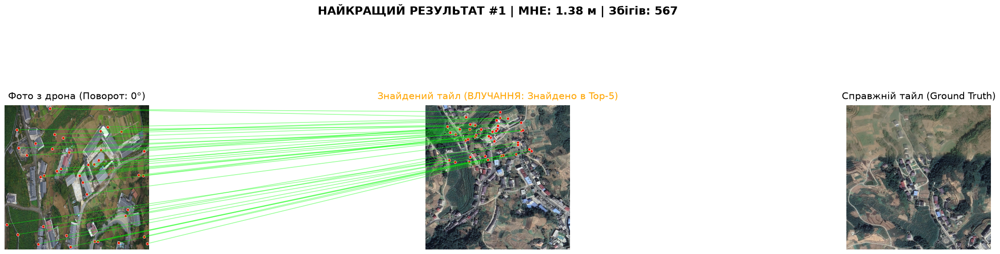

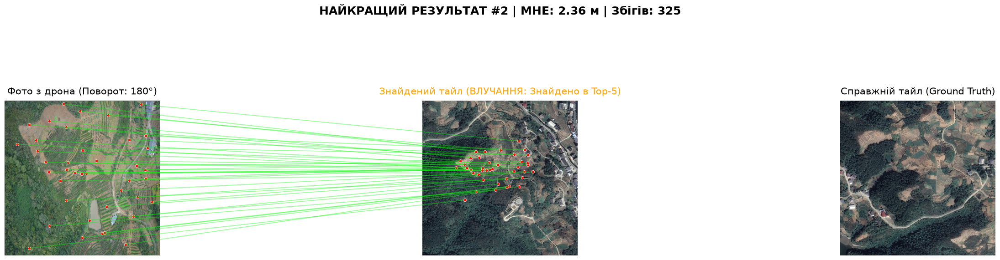

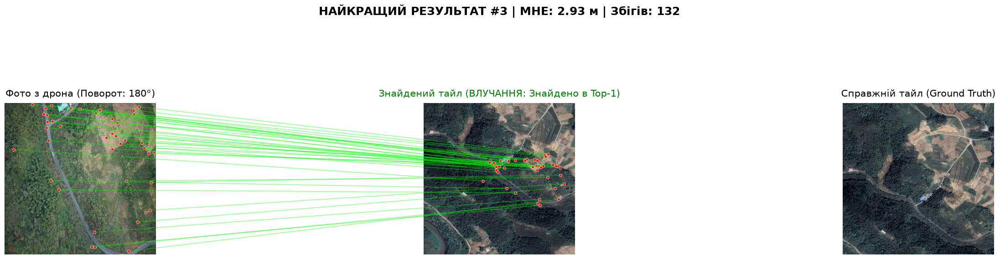

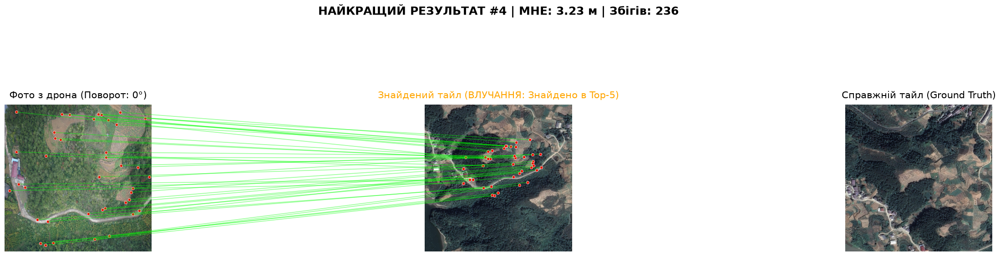

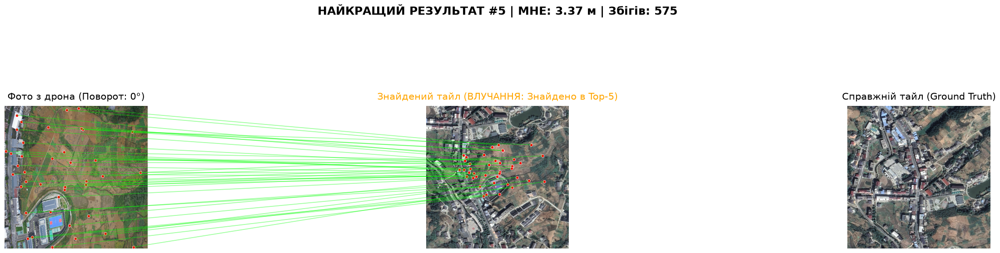

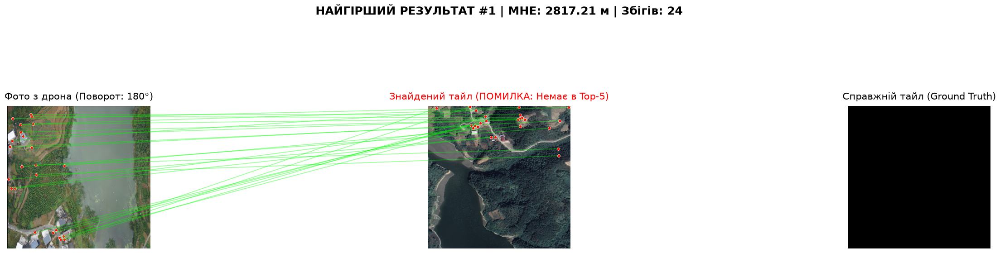

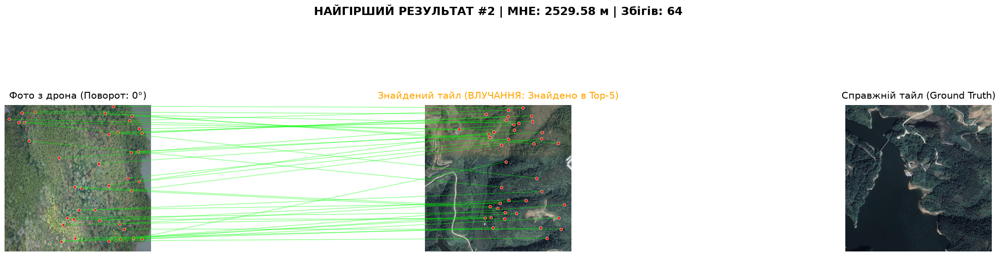

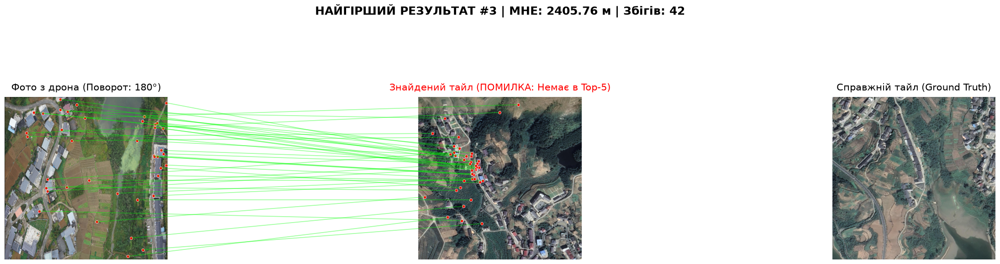

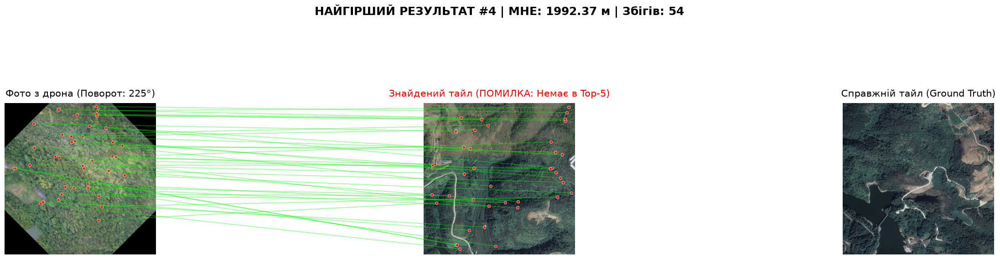

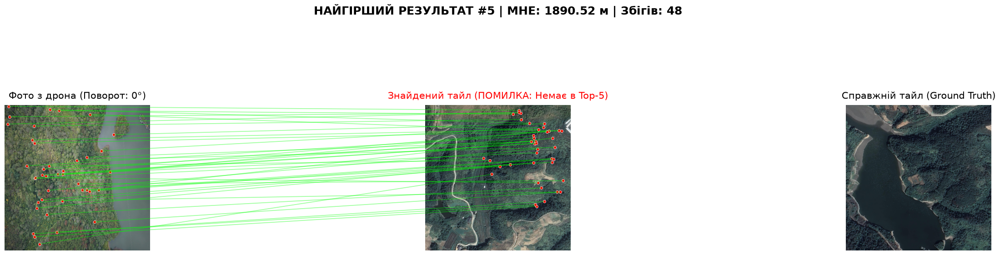


ФІНАЛЬНІ МЕТРИКИ
Top-1 Accuracy:  28.49%
Top-5 Accuracy:  66.28%
Mean Haversine Error (MHE): 471.55 m
Median Error: 346.04 m
P90 Error: 1333.72 m



,filename,gt_lat,gt_lon,pred_lat,pred_lon,error_m,lightglue_matches
0,06_0301.JPG,32.367881,109.642968,32.367870,109.642975,1.38,567
1,06_0332.JPG,32.358296,109.644458,32.358310,109.644439,2.36,325
2,06_0060.JPG,32.364787,109.638740,32.364770,109.638764,2.93,132
3,06_0029.JPG,32.359820,109.642189,32.359849,109.642193,3.23,236
4,06_0198.JPG,32.359837,109.649225,32.359836,109.649189,3.37,575
...,...,...,...,...,...,...,...
339,06_0079.JPG,32.354909,109.642098,32.370355,109.650510,1890.52,48
340,06_0001.JPG,32.351541,109.646761,32.369371,109.648851,1992.37,54
341,06_0100.JPG,32.351277,109.655699,32.368791,109.640662,2405.76,42
342,06_0005.JPG,32.349461,109.647460,32.372168,109.649088,2529.58,64


In [ ]:
results.sort(key=lambda x: x['mhe'])

top_5_best = results[:5]
top_5_worst = results[-5:]

for i, item in enumerate(top_5_best):
    plot_custom(item, f"BEST RESULT #{i+1} | MHE: {item['mhe']:.2f} м | Matches: {item['matches_count']}")

for i, item in enumerate(reversed(top_5_worst)):
    plot_custom(item, f"WORST RESULT #{i+1} | MHE: {item['mhe']:.2f} м | Matches: {item['matches_count']}")

df_results = pd.DataFrame([{
    'filename': r['filename'],
    'gt_lat': r['gt_lat'],
    'gt_lon': r['gt_lon'],
    'pred_lat': r['pred_lat'],
    'pred_lon': r['pred_lon'],
    'error_m': round(r['mhe'], 2),
    'lightglue_matches': r['matches_count']
} for r in results])

mean_error = np.mean([r['mhe'] for r in results])
median_error = np.median([r['mhe'] for r in results])
p90_error = np.percentile([r['mhe'] for r in results], 90)

print("\n" + "="*50)
print("FINAL METRICS")
print("="*50)
print(f"Top-1 Accuracy:  {top1_correct / len(df_uav) * 100:.2f}%")
print(f"Top-5 Accuracy:  {top5_correct / len(df_uav) * 100:.2f}%")
print(f"Mean Haversine Error (MHE): {mean_error:.2f} m")
print(f"Median Error: {median_error:.2f} m")
print(f"P90 Error: {p90_error:.2f} m")
print("="*50 + "\n")

display(df_results)